# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [28]:
import pandas as pd
import plotly.express as px


## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: Where did magnitude 3.5 or larger earthquakes occur in the selected California-region box from January through June 2025, and how did monthly counts differ north and south of latitude 36? I expect clusters rather than evenly spaced events, with counts changing by month. Location shows where the events occurred, while time shows whether activity stayed similar or changed.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: I used the **USGS Earthquake Catalog**, published by the U.S. Geological Survey. Downloaded November 9, 2026.

- Direct filtered CSV: [USGS download](https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime=2025-01-01&endtime=2025-06-30T23:59:59.999&minlatitude=32&maxlatitude=42&minlongitude=-125&maxlongitude=-114&minmagnitude=3.5&eventtype=earthquake&orderby=time-asc)
- Dictionary: [USGS CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php)
- Query filters: [USGS API documentation](https://earthquake.usgs.gov/fdsnws/event/1/)
- Saved file: `data/california_region_earthquakes_2025_h1.csv`

The request covers January 1 through June 30, 2025 UTC, latitude 32 to 42, longitude -125 to -114, magnitude 3.5 or higher, and earthquake events only. No lookup or boundary files are needed. Plotly supplies the map outlines, which may need internet access.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: Each row is one recorded earthquake detected and located by seismic networks. The download covers the stated box near California during the first six months of 2025. It includes offshore areas, nearby states, and northern Baja California in Mexico, so it is not a California state-boundary selection. Magnitudes and locations are catalog estimates and may be revised.

In [29]:
earthquakes_df = pd.read_csv("data/california_region_earthquakes_2025_h1.csv")
earthquakes_df["time"] = pd.to_datetime(earthquakes_df["time"], utc=True)


In [30]:
earthquakes_df.head()


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2025-01-02 02:34:04.660000+00:00,38.845500,-122.756333,1.42,4.65,mw,115,44.00,0.009316,0.0800,...,2026-07-29T03:08:11.561Z,"4 km NW of Cobb, CA",earthquake,0.09,0.15,NaN,21.0,reviewed,nc,nc
1,2025-01-05 07:54:43.820000+00:00,38.362800,-115.826800,4.50,3.60,ml,16,121.21,0.190000,0.1522,...,2025-03-17T21:34:44.040Z,"80 km N of Rachel, Nevada",earthquake,NaN,2.10,0.34,10.0,reviewed,nn,nn
2,2025-01-12 16:49:21.980000+00:00,37.960167,-122.042500,11.75,3.54,mw,187,21.00,0.012980,0.2700,...,2025-11-24T14:37:02.887Z,"2 km ENE of Pleasant Hill, CA",earthquake,0.14,0.27,NaN,5.0,reviewed,nc,nc
3,2025-01-18 10:20:06.193000+00:00,38.488800,-118.480100,7.40,3.70,mw,18,48.30,0.143000,0.1294,...,2025-03-29T22:12:42.040Z,"13 km ESE of Hawthorne, Nevada",earthquake,NaN,2.10,NaN,NaN,reviewed,nn,nn
4,2025-01-19 12:36:54.160000+00:00,40.278667,-124.501833,19.99,3.86,mw,62,247.00,0.122200,0.1600,...,2025-03-29T22:12:43.040Z,"19 km W of Petrolia, CA",earthquake,0.53,0.25,NaN,14.0,reviewed,nc,nc


In [31]:
earthquakes_df.tail()


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
45,2025-06-06 07:16:12.812000+00:00,37.266000,-114.642400,4.30,4.00,mw,12,87.08,0.35400,0.1596,...,2026-06-06T07:26:22.887Z,"40 km SSW of Caliente, Nevada",earthquake,NaN,4.10,NaN,NaN,reviewed,nn,nn
46,2025-06-13 07:44:47.750000+00:00,40.334167,-124.881000,8.99,4.08,mw,185,230.00,0.41420,0.3000,...,2025-08-22T20:26:00.040Z,"51 km WNW of Petrolia, CA",earthquake,0.47,0.74,NaN,14.0,reviewed,nc,nc
47,2025-06-27 10:57:11.200000+00:00,40.609167,-122.418833,20.59,3.60,mw,36,38.00,0.04376,0.2200,...,2026-06-24T15:35:41.476Z,"5 km NW of Redding, CA",earthquake,0.40,0.34,NaN,21.0,reviewed,nc,nc
48,2025-06-29 02:37:58.310000+00:00,37.316000,-117.920667,11.60,4.54,mw,65,69.00,0.30130,0.1000,...,2026-06-29T02:48:09.929Z,"8 km SSE of Deep Springs, CA",earthquake,0.23,0.57,NaN,12.0,reviewed,nc,nc
49,2025-06-29 03:56:19.230000+00:00,37.326500,-117.919167,11.69,3.87,mw,60,69.00,0.30560,0.1000,...,2025-09-04T20:40:01.040Z,"8 km SE of Deep Springs, CA",earthquake,0.28,0.59,NaN,9.0,reviewed,nc,nc


In [32]:
earthquakes_df.shape


(50, 22)

In [33]:
earthquakes_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   time             50 non-null     datetime64[us, UTC]
 1   latitude         50 non-null     float64            
 2   longitude        50 non-null     float64            
 3   depth            50 non-null     float64            
 4   mag              50 non-null     float64            
 5   magType          50 non-null     str                
 6   nst              50 non-null     int64              
 7   gap              50 non-null     float64            
 8   dmin             50 non-null     float64            
 9   rms              50 non-null     float64            
 10  net              50 non-null     str                
 11  id               50 non-null     str                
 12  updated          50 non-null     str                
 13  place            50 non-null     

In [34]:
earthquakes_df.isnull().sum()


time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                 0
gap                 0
dmin                0
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError    10
depthError          0
magError           37
magNst              7
status              0
locationSource      0
magSource           0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| `time` | Event origin date and time in UTC | Temporal | datetime64[us, UTC] | 0 |
| `latitude` | Epicenter latitude in decimal degrees north | Quantitative | float64 | 0 |
| `longitude` | Epicenter longitude in decimal degrees east, negative in this area | Quantitative | float64 | 0 |
| `mag` | Reported earthquake magnitude, not a damage measurement | Quantitative | float64 | 0 |
| `id` | Catalog event ID | Categorical identifier | str | 0 |
| `place` | Location description | Categorical | str | 0 |
| `region` | Latitude 36 or higher versus below 36 | Categorical | str | 0 |
| `month` | UTC event month in YYYY-MM form | Temporal | str | 0 |
| `earthquake_count` | Number of selected events per region-month | Quantitative | int64 | 0 |

Use quantitative, categorical, or temporal for feature type.

Your answer: Original file values are kept. Derived fields are described in the table.


**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer: I kept records with a time, location, and magnitude of at least 3.5 within the selected dates and area. North means latitude 36 or higher. South means below 36. Each earthquake counts once, regardless of magnitude. A zero means the file has no qualifying events for that area and month.

In [35]:
earthquakes_analysis_df = earthquakes_df.dropna(subset=["time", "latitude", "longitude", "mag"]).copy()
earthquakes_analysis_df["region"] = "South of 36N"
earthquakes_analysis_df.loc[earthquakes_analysis_df["latitude"] >= 36, "region"] = "36N and north"
earthquakes_analysis_df["month"] = earthquakes_analysis_df["time"].dt.strftime("%Y-%m")
earthquakes_analysis_df = earthquakes_analysis_df.sort_values("time")
print("Original rows:", len(earthquakes_df))
print("Retained rows:", len(earthquakes_analysis_df))
print("Invalid coordinate rows:", (~earthquakes_analysis_df["latitude"].between(32, 42) | ~earthquakes_analysis_df["longitude"].between(-125, -114)).sum())
print("Duplicate event IDs:", earthquakes_analysis_df["id"].duplicated().sum())


Original rows: 50
Retained rows: 50
Invalid coordinate rows: 0
Duplicate event IDs: 0


In [36]:
month_order = pd.period_range("2025-01", "2025-06", freq="M").astype(str).tolist()
earthquake_grid = pd.crosstab(earthquakes_analysis_df["region"], earthquakes_analysis_df["month"])
earthquake_grid = earthquake_grid.reindex(index=["36N and north", "South of 36N"], columns=month_order, fill_value=0)
earthquake_monthly_df = earthquake_grid.T.rename_axis("month").reset_index().melt(
    id_vars="month", var_name="region", value_name="earthquake_count"
).sort_values(["region", "month"])
earthquake_monthly_df


,month,region,earthquake_count
0,2025-01,36N and north,6
1,2025-02,36N and north,7
2,2025-03,36N and north,5
3,2025-04,36N and north,5
4,2025-05,36N and north,9
5,2025-06,36N and north,5
6,2025-01,South of 36N,1
7,2025-02,South of 36N,3
8,2025-03,South of 36N,4
9,2025-04,South of 36N,4


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: No rows were removed. All 50 earthquake records have the required values. The map uses one row per event. The count summary has one row per geographic half per month, including the southern half's zero count in June.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I will use a point map and a monthly line chart. The map uses latitude and longitude, region colors, and magnitude-sized markers, with event time in hover. The line chart uses month on the horizontal axis, event count on the vertical axis, and one color per region. Both use the same 50 events. Marker size shows magnitude, not earthquake damage or affected land area.

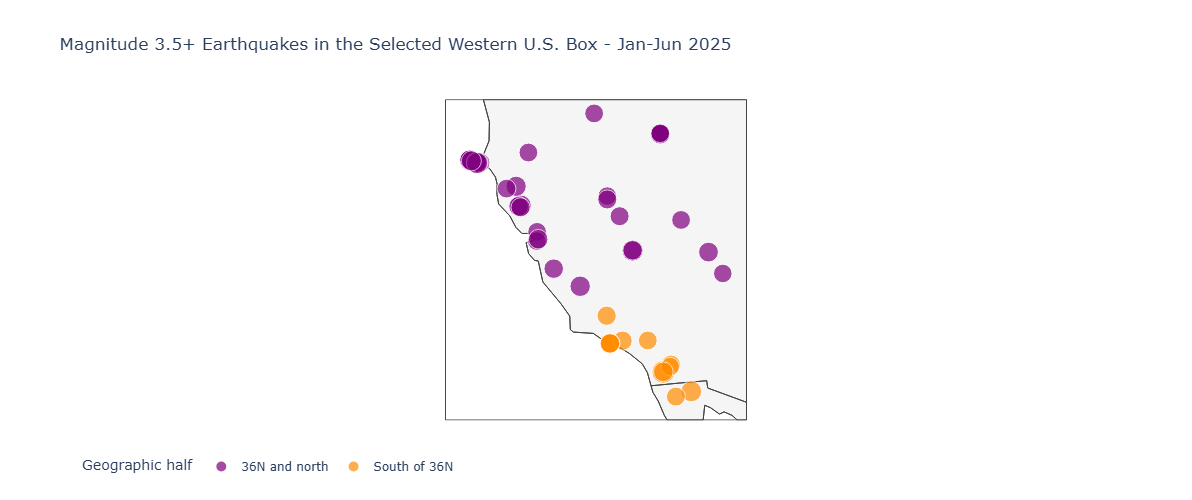

In [37]:
earthquake_map = px.scatter_geo(
    earthquakes_analysis_df, lat="latitude", lon="longitude", color="region", size="mag",
    size_max=16, hover_name="place", hover_data=["id", "time", "mag"],
    color_discrete_map={"36N and north": "purple", "South of 36N": "darkorange"},
    labels={"region": "Geographic half", "mag": "Magnitude", "time": "Event time (UTC)"},
    title="Magnitude 3.5+ Earthquakes in the Selected Western U.S. Box - Jan-Jun 2025"
)
earthquake_map.update_geos(
    projection_type="mercator", lataxis_range=[31.5, 42.5], lonaxis_range=[-126, -113],
    showland=True, landcolor="whitesmoke", showcountries=True, showsubunits=True
)
earthquake_map.update_layout(height=500, legend_orientation="h", legend_y=-0.1)
earthquake_map.show(renderer="notebook_connected+plotly_mimetype")


**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer: The events form clusters instead of filling the box evenly. There are 37 north of or at latitude 36 and 13 south of it. The largest event is magnitude 5.21 near Julian, California, on April 14, 2025. The map connects each marker with its location and event time, but overlapping points can hide some events.

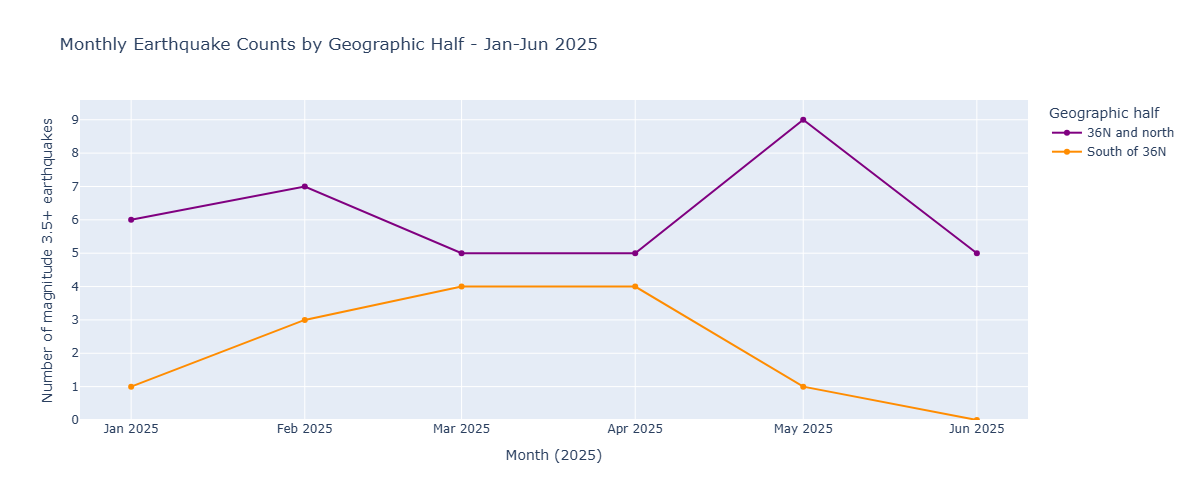

In [38]:
earthquake_line = px.line(
    earthquake_monthly_df, x="month", y="earthquake_count", color="region", markers=True,
    category_orders={"month": month_order},
    color_discrete_map={"36N and north": "purple", "South of 36N": "darkorange"},
    labels={"month": "Month (2025)", "earthquake_count": "Number of magnitude 3.5+ earthquakes", "region": "Geographic half"},
    title="Monthly Earthquake Counts by Geographic Half - Jan-Jun 2025"
)
earthquake_line.update_layout(height=500)
earthquake_line.update_yaxes(rangemode="tozero", dtick=1)
earthquake_line.show(renderer="notebook_connected+plotly_mimetype")


**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: The line chart shows when each geographic half had more events. The northern half peaks at 9 in May 2025, while the southern half peaks at 4 in both March and April. Southern June has 0 qualifying events. Unlike the map, this chart makes month-to-month counts easy to compare.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [39]:
earthquakes_analysis_df.loc[
    earthquakes_analysis_df["id"].isin(["ci40930319", "nc75183327"]),
    ["id", "time", "place", "latitude", "longitude", "mag", "region"]
]


,id,time,place,latitude,longitude,mag,region
33,ci40930319,2025-04-16 18:59:21.600000+00:00,"61 km ENE of Ensenada, B.C., MX",32.139833,-116.052167,3.65,South of 36N
40,nc75183327,2025-05-17 05:51:18.640000+00:00,"30 km W of Petrolia, CA",40.274167,-124.626500,3.50,36N and north


In [40]:
pd.crosstab(earthquakes_analysis_df["month"], earthquakes_analysis_df["region"]).reindex(month_order, fill_value=0)


region,36N and north,South of 36N
month,,
2025-01,6,1
2025-02,7,3
2025-03,5,4
2025-04,5,4
2025-05,9,1
2025-06,5,0


In [41]:
print("Times sorted:", earthquakes_analysis_df["time"].is_monotonic_increasing)
print("Event total from monthly counts:", earthquake_monthly_df["earthquake_count"].sum())
print("Southern events in June:", len(earthquakes_analysis_df.loc[(earthquakes_analysis_df["month"] == "2025-06") & (earthquakes_analysis_df["region"] == "South of 36N")]))


Times sorted: True
Event total from monthly counts: 50
Southern events in June: 0


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked two map hover values against the source rows. Event ci40930319 is magnitude 3.65 near Ensenada, Mexico, on April 16, 2025, in the southern half. Event nc75183327 is magnitude 3.50 west of Petrolia, California, on May 17, in the northern half. Their dates, magnitudes, and locations agree. Monthly counts sum to all 50 events, dates are sorted, and the source has no southern June event. That zero means no magnitude 3.5+ event in this snapshot, not no earthquakes at all.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: Where did magnitude 3.5+ earthquakes occur in the selected box in January through June 2025, and how did monthly counts differ north and south of latitude 36? The map shows clusters, including near the northern California coast and the southern border area. The northern half has 37 events versus 13 in the southern half. The line chart shows the northern peak of 9 in May, southern peaks of 4 in March and April, and 0 southern events in June. The largest mapped event is magnitude 5.21 near Julian on April 14. These results support the prediction of clusters and changing monthly counts.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: First, these counts depend on the magnitude cutoff, geographic box, and catalog coverage. They are not earthquake risk or damage rates, and the two geographic halves do not have equal areas. Second, six months cannot show a long-term pattern or predict the next event, and catalog estimates can be revised. The map makes clusters and individual locations clear but can hide overlapping events. The line chart shows monthly changes clearly but hides locations within each half.

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: How did monthly mean temperature differ between the Miami and Seattle airport stations during 2024? I expect Miami to stay warmer, with Seattle showing a larger winter-to-summer change. Looking at both stations and all twelve months keeps a place difference from being confused with a seasonal change.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: I used **Global Surface Summary of the Day (GSOD)**, published by NOAA's National Centers for Environmental Information. Downloaded November 9, 2026.

- Direct filtered CSV: [NOAA download](https://www.ncei.noaa.gov/access/services/data/v1?dataset=global-summary-of-the-day&stations=72202012839,72793024233&startDate=2024-01-01&endDate=2024-12-31&format=csv&includeStationLocation=1&includeStationName=1&dataTypes=TEMP)
- Dictionary: [GSOD readme](https://www.ncei.noaa.gov/data/global-summary-of-the-day/doc/readme.txt)
- Collection context: [NOAA dataset overview](https://www.ncei.noaa.gov/metadata/geoportal/rest/metadata/item/gov.noaa.ncdc%3AC00516/html)
- Saved file: `data/miami_seattle_daily_temperature_2024.csv`

The request selects daily mean temperature for stations 72202012839 and 72793024233 from January 1 through December 31, 2024. Station names and coordinates are included in the download. No outside lookup file is needed. TEMP is in degrees Fahrenheit.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: Each row is one airport station's daily summary. The file covers Miami International Airport and Seattle-Tacoma Airport for 2024. NOAA builds the daily summaries from hourly or synoptic station readings, using GMT days and at least four observations. The monthly values here are averages of the available daily means, not one temperature reading or a citywide measurement.

In [42]:
weather_df = pd.read_csv(
    "data/miami_seattle_daily_temperature_2024.csv",
    dtype={"STATION": "str"}, na_values={"TEMP": [9999.9]}
)
weather_df["DATE"] = pd.to_datetime(weather_df["DATE"])


In [43]:
weather_df.head()


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TEMP
0,72202012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694,1.4,2024-01-01,62.1
1,72202012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694,1.4,2024-01-02,63.0
2,72202012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694,1.4,2024-01-03,63.2
3,72202012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694,1.4,2024-01-04,68.8
4,72202012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694,1.4,2024-01-05,69.2


In [44]:
weather_df.tail()


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TEMP
727,72793024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2024-12-27,45.1
728,72793024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2024-12-28,47.2
729,72793024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2024-12-29,45.4
730,72793024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2024-12-30,42.1
731,72793024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2024-12-31,41.2


In [45]:
weather_df.shape


(732, 7)

In [46]:
weather_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   STATION    732 non-null    str           
 1   NAME       732 non-null    str           
 2   LATITUDE   732 non-null    float64       
 3   LONGITUDE  732 non-null    float64       
 4   ELEVATION  732 non-null    float64       
 5   DATE       732 non-null    datetime64[us]
 6   TEMP       732 non-null    float64       
dtypes: datetime64[us](1), float64(4), str(2)
memory usage: 70.5 KB


In [47]:
weather_df.isnull().sum()


STATION      0
NAME         0
LATITUDE     0
LONGITUDE    0
ELEVATION    0
DATE         0
TEMP         0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| `STATION` | Station identifier stored as text | Categorical identifier | str | 0 |
| `NAME` | Official station name | Categorical | str | 0 |
| `LATITUDE` | Station latitude in decimal degrees north | Quantitative | float64 | 0 |
| `LONGITUDE` | Station longitude in decimal degrees east | Quantitative | float64 | 0 |
| `DATE` | Date of the GMT daily summary | Temporal | datetime64[us] | 0 |
| `TEMP` | Daily mean temperature in degrees Fahrenheit, missing code 9999.9 | Quantitative | float64 | 0 |
| `city` | Miami or Seattle, mapped from station IDs | Categorical | str | 0 |
| `month` | Observation month in YYYY-MM form | Temporal | str | 0 |
| `mean_temperature_f` | Mean of daily TEMP values in a station-month, Fahrenheit | Quantitative | float64 | 0 |
| `day_count` | Usable daily temperature records in a station-month | Quantitative | int64 | 0 |

Use quantitative, categorical, or temporal for feature type.

Your answer: Original file values are kept. Derived fields are described in the table.


**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer: I will use daily mean temperature for the two stations throughout 2024. The station IDs stay as text. The dictionary's 9999.9 temperature code becomes missing, not a real temperature. Zero degrees Fahrenheit would stay a valid value. Rows missing a date, station, or temperature would be excluded, but none are missing here. Monthly means give each day's mean equal weight. Day counts stay visible so missing days would not look like complete coverage.

In [48]:
weather_analysis_df = weather_df.dropna(subset=["STATION", "DATE", "TEMP"]).copy()
weather_analysis_df["city"] = weather_analysis_df["STATION"].map({
    "72202012839": "Miami", "72793024233": "Seattle"
})
weather_analysis_df["month"] = weather_analysis_df["DATE"].dt.strftime("%Y-%m")
weather_analysis_df = weather_analysis_df.sort_values(["city", "DATE"])
print("Original rows:", len(weather_df))
print("Retained rows:", len(weather_analysis_df))
print("Unmatched station IDs:", weather_analysis_df["city"].isnull().sum())
weather_analysis_df[["STATION", "city", "LATITUDE", "LONGITUDE"]].drop_duplicates()


Original rows: 732
Retained rows: 732
Unmatched station IDs: 0


,STATION,city,LATITUDE,LONGITUDE
0,72202012839,Miami,25.78805,-80.31694
366,72793024233,Seattle,47.44467,-122.31442


In [49]:
weather_monthly_df = weather_analysis_df.groupby(["city", "month"]).agg(
    mean_temperature_f=("TEMP", "mean"), day_count=("TEMP", "count")
).reset_index().sort_values(["city", "month"])
weather_monthly_df


,city,month,mean_temperature_f,day_count
0,Miami,2024-01,70.609677,31
1,Miami,2024-02,68.713793,29
2,Miami,2024-03,75.454839,31
3,Miami,2024-04,75.833333,30
4,Miami,2024-05,83.064516,31
5,Miami,2024-06,82.626667,30
6,Miami,2024-07,85.238710,31
7,Miami,2024-08,84.445161,31
8,Miami,2024-09,84.006667,30
9,Miami,2024-10,79.738710,31


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: No rows were removed. There are 732 daily records, 366 for each station because 2024 was a leap year. The monthly summary has 24 rows, one station-month each. Each mean uses all daily values available for that station and month.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I will use a line chart and a location-by-month heatmap. Both use the same 24 monthly means in degrees Fahrenheit. The line chart uses month, temperature, and city color. The heatmap puts the two cities in rows, months in columns, and uses color for temperature. Location is shown by the station's city label rather than a map. This keeps the place and time comparisons together without needing map boundaries.

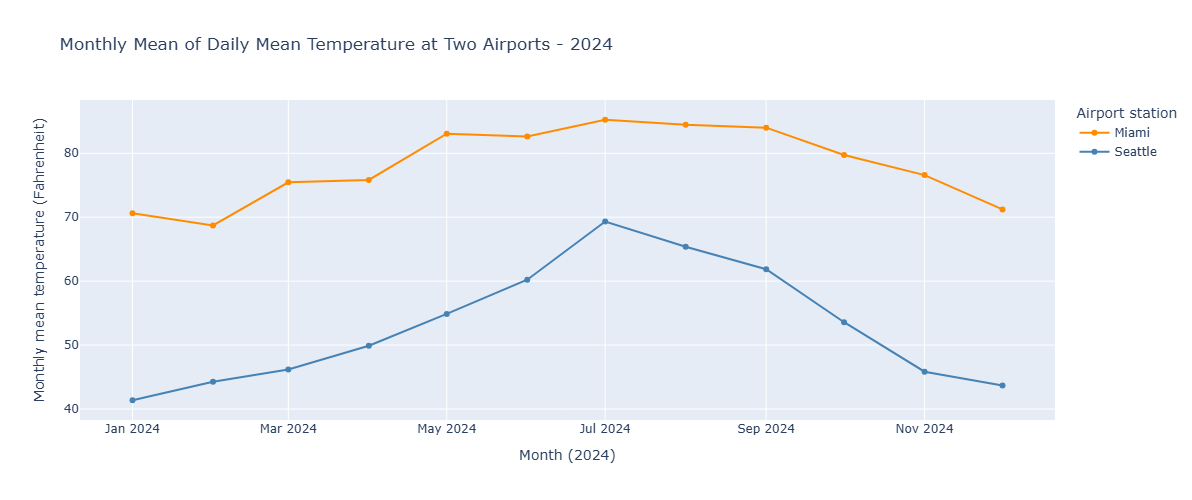

In [50]:
weather_line = px.line(
    weather_monthly_df, x="month", y="mean_temperature_f", color="city", markers=True,
    hover_data={"day_count": True, "mean_temperature_f": ":.2f"},
    color_discrete_map={"Miami": "darkorange", "Seattle": "steelblue"},
    labels={"month": "Month (2024)", "mean_temperature_f": "Monthly mean temperature (Fahrenheit)", "city": "Airport station", "day_count": "Days used"},
    title="Monthly Mean of Daily Mean Temperature at Two Airports - 2024"
)
weather_line.update_layout(height=500)
weather_line.show(renderer="notebook_connected+plotly_mimetype")


**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer: Miami is warmer in every month, and both stations warm up toward summer before cooling again. In January 2024, Miami averages 70.61 degrees Fahrenheit compared with Seattle's 41.37. Both peak in July, at 85.24 for Miami and 69.32 for Seattle. The lines make the seasonal change and the gap between places easy to follow.

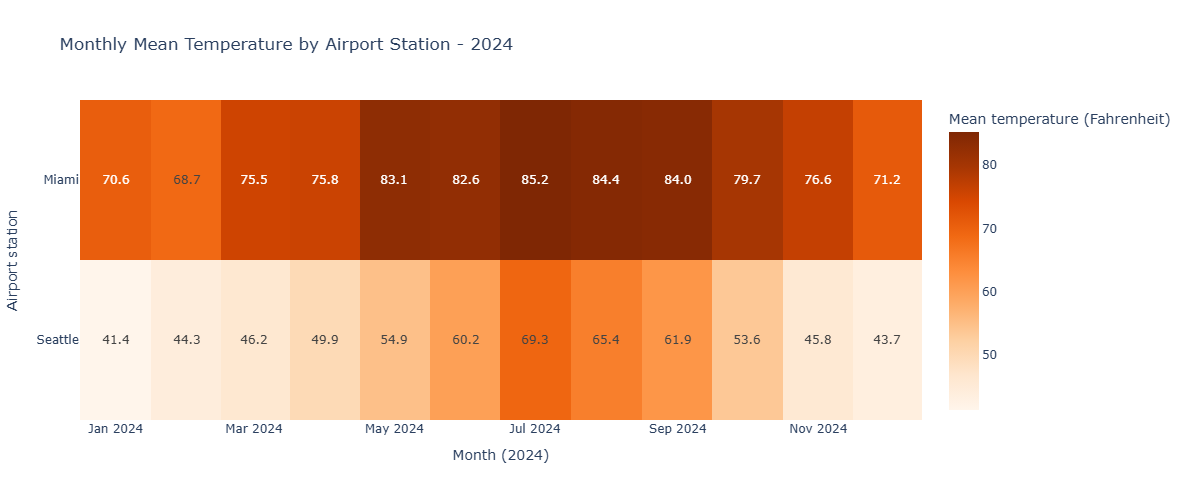

In [51]:
weather_grid = weather_monthly_df.pivot(index="city", columns="month", values="mean_temperature_f")
weather_grid = weather_grid.reindex(index=["Miami", "Seattle"], columns=sorted(weather_grid.columns))
weather_heatmap = px.imshow(
    weather_grid, aspect="auto", color_continuous_scale="Oranges", text_auto=".1f",
    labels={"x": "Month (2024)", "y": "Airport station", "color": "Mean temperature (Fahrenheit)"},
    title="Monthly Mean Temperature by Airport Station - 2024"
)
weather_heatmap.update_layout(height=500)
weather_heatmap.show(renderer="notebook_connected+plotly_mimetype")


**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: The heatmap puts both station-month values side by side in a compact view. For example, July shows 85.2 degrees Fahrenheit in Miami and 69.3 in Seattle. Temperatures in these answers are rounded to two decimal places, or one decimal place when reading the heatmap labels. The darker summer cells and lighter winter cells show the same seasonal pattern as the lines. The heatmap makes individual months easy to compare, while the line chart makes the size and direction of changes clearer.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [52]:
weather_analysis_df.loc[
    ((weather_analysis_df["city"] == "Miami") & (weather_analysis_df["month"] == "2024-01"))
    | ((weather_analysis_df["city"] == "Seattle") & (weather_analysis_df["month"] == "2024-07"))
].groupby(["city", "month"])["TEMP"].agg(["count", "mean", "min", "max"])


,,count,mean,min,max
city,month,,,,
Miami,2024-01,31,70.609677,60.7,77.3
Seattle,2024-07,31,69.322581,61.3,81.4


In [53]:
weather_analysis_df.groupby("city")["DATE"].agg(["count", "min", "max"])


,count,min,max
city,,,
Miami,366,2024-01-01,2024-12-31
Seattle,366,2024-01-01,2024-12-31


In [54]:
print("Daily duplicates:", weather_analysis_df.duplicated(["STATION", "DATE"]).sum())
print("Sorted monthly sequences:", weather_monthly_df.groupby("city")["month"].is_monotonic_increasing.all())
print("All month day counts complete:", (weather_monthly_df["day_count"].to_numpy() == pd.to_datetime(weather_monthly_df["month"]).dt.days_in_month.to_numpy()).all())
weather_monthly_df.loc[weather_monthly_df.groupby("city")["mean_temperature_f"].idxmin()]


Daily duplicates: 0
Sorted monthly sequences: True
All month day counts complete: True


,city,month,mean_temperature_f,day_count
1,Miami,2024-02,68.713793,29
12,Seattle,2024-01,41.367742,31


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked Miami's January hover value of 70.61 degrees Fahrenheit and Seattle's July value of 69.32 against the daily records. Each calculation uses 31 days and agrees with the plotted value. Dates and months are sorted. Each station has 366 unique daily records, and every month's day count is complete. Miami's lowest monthly mean is February at 68.71, not January. The two station IDs match their supplied names and coordinates.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: How did monthly mean temperature differ between the Miami and Seattle airport stations during 2024? Both figures show Miami warmer in every month. In January the means are 70.61 and 41.37 degrees Fahrenheit, and in July they are 85.24 and 69.32. Miami ranges from a February low of 68.71 to a July high of 85.24, a change of 16.53 degrees. Seattle ranges from 41.37 in January to 69.32 in July, a change of 27.95 degrees. The line chart shows Seattle's larger seasonal swing, while the heatmap shows which months are warmest at each place. Both parts of the prediction fit.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: First, these are two airport stations, not the average temperature across either whole city. Second, one year does not establish a long-term climate trend, and monthly means hide daily highs, lows, and short weather events. The line chart makes changes and gaps between stations easier to compare. The heatmap makes place-by-month patterns compact, but color alone makes small differences harder to judge. Its numeric labels help.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I did ask AI to help check some of my code for the bar graphs because I was getting confused with how the data was being displayed. I originally had the data grouped incorrectly, which caused some of the values to be wrong. I was able to see that it was wrong but quickly lost myself in the data, so AI helped me correct the grouping and make sure the graphs were showing the right information. I checked the results to make sure everything looked correct.

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.